# Decode & Detect: LightGBM money-laundering detector (v10)

**In one sentence:** we give every payment a score between 0 (looks normal) and 1 (looks like money laundering), so that the suspicious payments float to the top of the list.

**How we get there, in plain English**
1. **Read** the raw ledger files.
2. **Tidy** them: one row per payment, with every amount converted to US dollars.
3. **Look** at the data with pictures, to see what laundering looks like compared with normal activity.
4. **Describe** every payment with numbers ("features"). Examples: how fast the receiver passed the money on, and how many brand-new accounts are involved in its flow. **New in v8:** we describe the whole scenario a payment belongs to, not just the single payment.
5. **Train** a LightGBM model (many small decision trees voting together) and test it fairly with 5-fold cross-validation on scenarios it has never seen.
6. **Diagnose:** which features and rules helped, which didn't, and where the model still fails.
7. **Write** the submission CSV.
8. **Summary:** problems, what went well, what to do next, and what each chart means.

**New in v10 (built on v9). Why v8 and v9 lost precision on the leaderboard, and the fix:**
- **Account fingerprints removed.** A model could tell train payments from test payments perfectly (AUC 1.0) using per-account *weekly totals*: total sent and received, typical hold time, weekly conversion share. They are constant for an account all week, so they act like an account ID. Train and held-out folds share accounts (there are only 700), so cross-validation rewarded memorising accounts; test has brand-new wallets, so that memory is useless. The 60 most account-specific features are dropped (separability falls to 0.88). Cross-validation barely changes, so they were never real signal.
- **A robust "core" model is blended in.** The core model uses only short-window flow features: 5-minute bursts, pass-through, chains. These look most alike between train and test (separability 0.76). Its ranking is averaged 50/50 with the full model's ranking. Cross-validation: overall 57.4 vs 56.8, top-1% precision 83.9% vs 82.4%, easy 0.777 vs 0.766, over 3 different splits. Trade-off: medium AP falls from 0.084 to 0.042.

**New in v9 (built on v8):**
- **Blob fix:** long link windows chained ~4,600 unrelated payments into one giant "scenario". Its statistics differed completely between train and test and fooled cross-validation. Components bigger than any real scenario (40+ payments) now get *no* scenario features.
- **Medium cases: compare each scenario with look-alikes of the same shape.** Medium laundering copies the decoys' shape but is slower, moves more money and passes on more of it. We rank speed, money, % passed on and conversion mix *within* scenarios of the same shape, plus a fuller (wider) medium grouping.
- **The 25 ambiguous payments are treated as noise:** zero weight in training (their labels are random by design). They are still scored.
- **Tested and rejected** (see 5b): a medium-only specialist model and two ways of rebuilding relay scenarios.

**Score used everywhere:** *average precision (AP)*. Think of it as "when the model says *this one is suspicious*, how often is it right, averaged as we walk down the ranked list". 1.0 is perfect. Guessing at random scores about 0.03 here, because only 3% of payments are suspicious.

## Base rules found in the labelled training data

| # | Case type | Rule in plain words | Evidence (train) |
|---|---|---|---|
| given | Easy | Laundering bursts are fast: only ~10% of innocent look-alikes finish within 3 minutes | easy hop delay median 44–450 s; decoys 380–4800 s |
| given | Medium | Medium cases are built to look like the innocent decoys: route, conversions, fees and night-time are no help (AUC 0.45–0.55) | confirmed |
| given | Medium | They are slower and move slightly more money (AUC 0.6–0.7) | duration AUC 0.68, gap AUC 0.70 |
| given | Distributed relay | The suspicious relay passes money on faster than its 99 siblings | hold-time percentile within cohort 0.03–0.42 |
| given | Aggregate relay | Bigger, more uneven amounts; largest payment in the top half | max-payment percentile 0.49–0.96 |
| new | Easy | Money is passed on almost whole: each hop keeps ~96% (decoys keep 83–89%) | per-hop ratio |
| new | Medium | Medium also keeps more per hop than decoys (0.91–0.96 vs 0.83–0.88) | per-hop ratio |
| new | Medium | Medium fan-in / fan-out move 3–10× more money than their decoys | scenario totals |
| new | All planted | ~95% of planted payments use a sender→receiver pair seen only once all week; normal commerce does so only ~28% of the time | pair recurrence |
| new | Relays | Relay cohorts have a fixed size and shape; suspicious relays forward each wave within 1.7–5.5 h | hop delays |
| new | Relays | Each relay hub is shared by ~3 scenarios, so per-account signals are diluted ~10× | hub reuse |
| new | None | SendMax is always exactly 1.01× the actual cost: no signal | every payment |
| new | None | No payment converts back into exactly the same asset; every USD→USD path is a cross-issuer hop | route census |

## 1. Read the data

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import lightgbm as lgb
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import Markdown, display

import aml_features as af

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})
BLUE, ORANGE, RED, GREY, GREEN = "#4C78A8", "#F58518", "#E45756", "#BBBBBB", "#54A24B"

TRAIN_DIR, TEST_DIR = Path("train"), Path("test-data")
raw_pay, raw_legs, rates = af.load_split(TRAIN_DIR)
raw_test_pay, raw_test_legs, test_rates = af.load_split(TEST_DIR)
labels = pd.read_csv(TRAIN_DIR / "labels.csv")
print(f"train: {len(raw_pay):,} payments, {len(raw_legs):,} transfer legs | test: {len(raw_test_pay):,} payments")

train: 40,131 payments, 60,557 transfer legs | test: 40,101 payments


## 2. Tidy the data
This step removes duplicates and, for every payment, records what it actually cost (the first transfer leg), its route, the issuers it touched and the liquidity providers it used. It then checks that nothing is missing.

In [2]:
pay, legs = af.clean(raw_pay, raw_legs)
test_pay, test_legs = af.clean(raw_test_pay, raw_test_legs)
pay = pay.merge(labels, on="TRANSACTION_HASH", how="left")
assert pay.TRANSACTION_HASH.is_unique and test_pay.TRANSACTION_HASH.is_unique
print("missing USD values:", pay.dlv_usd.isna().sum(), "| missing labels:", pay.is_suspicious.isna().sum())
summary = pay.groupby(["difficulty", "is_suspicious"]).size().rename("payments").reset_index()
summary["meaning"] = summary.apply(lambda r: "innocent" if r.is_suspicious == 0 else f"laundering ({r.difficulty})", axis=1)
summary

missing USD values: 0 | missing labels: 0


,difficulty,is_suspicious,payments,meaning
0,easy,1,800,laundering (easy)
1,hard,1,225,laundering (hard)
2,medium,1,225,laundering (medium)
3,normal,0,38881,innocent


## 3. Look at the data
### 3a. What do the scenarios look like?

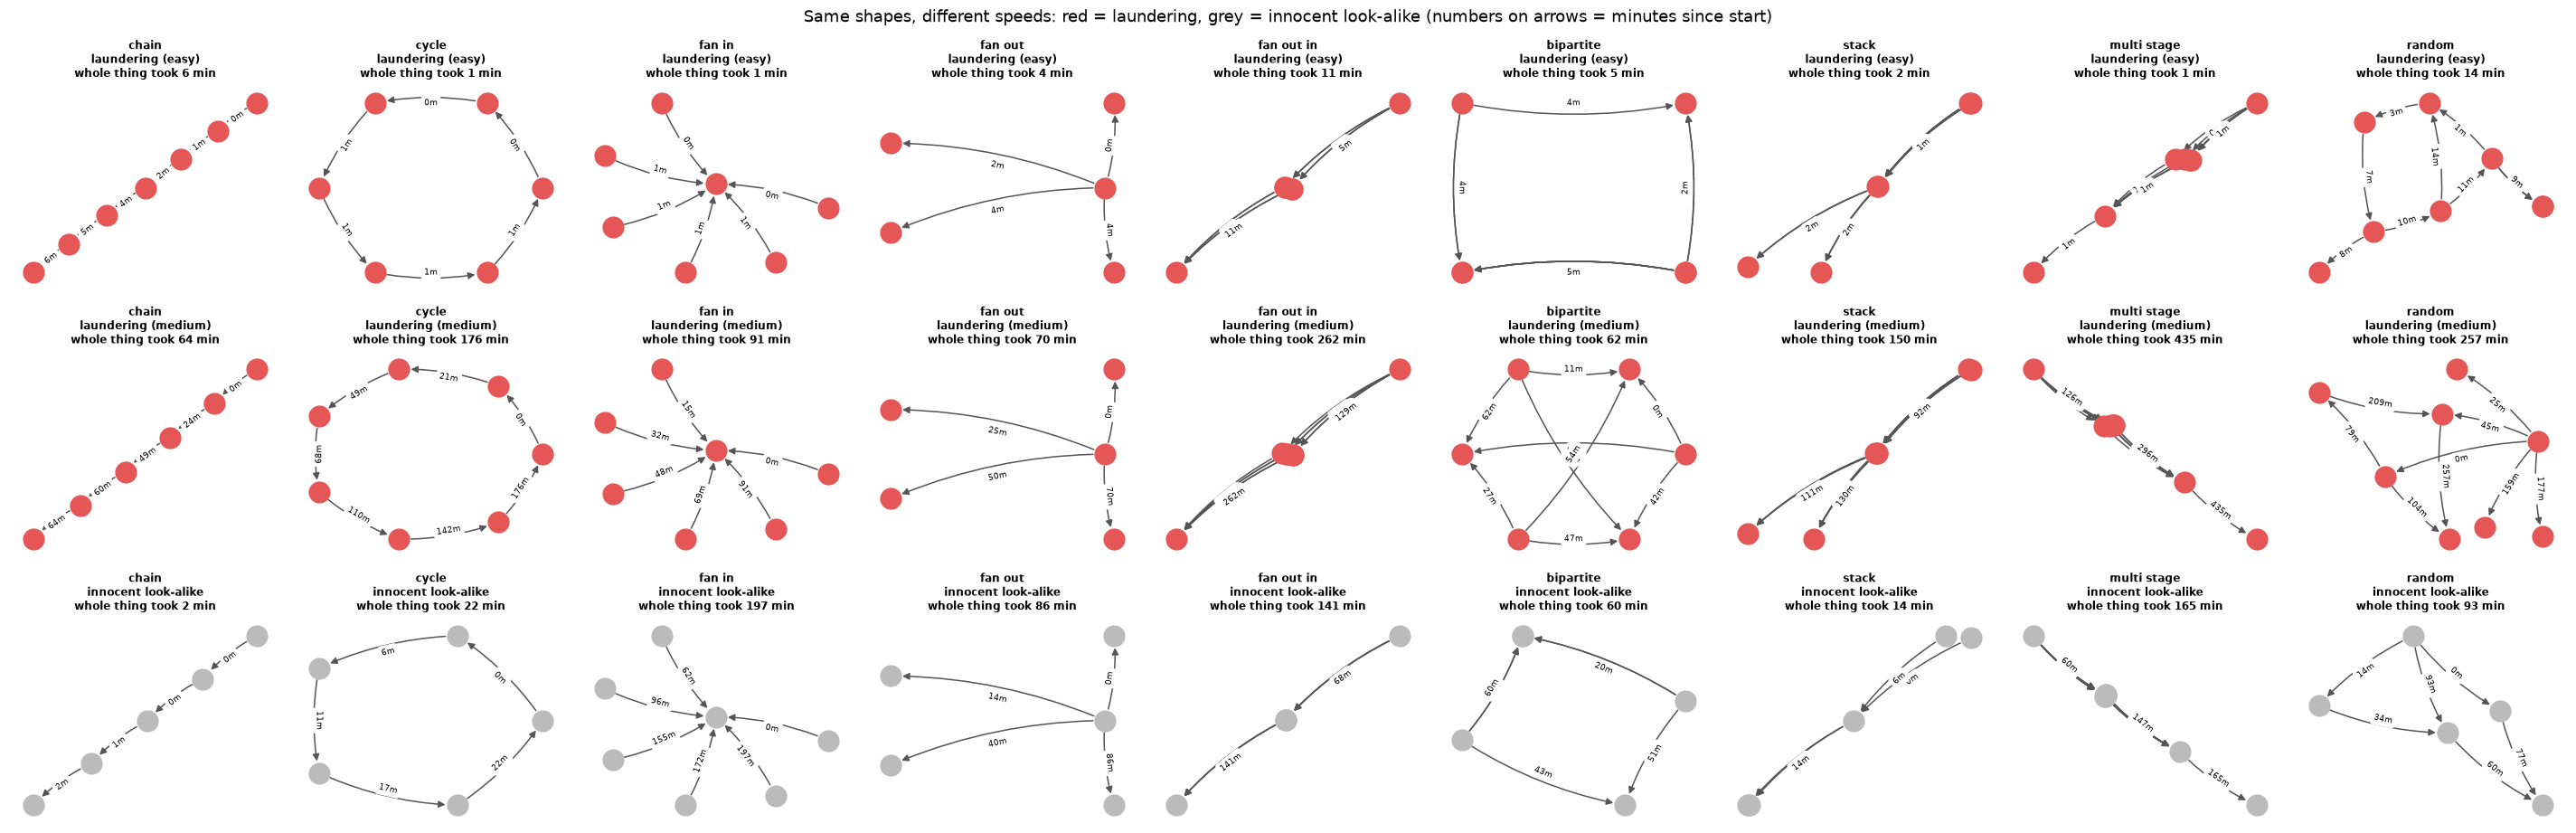

In [3]:
def draw_scenario(ax, d, title):
    d = d.sort_values("t")
    G = nx.MultiDiGraph()
    t0 = d.t.min()
    for r in d.itertuples():
        G.add_edge(r.sender[:5], r.receiver[:5], label=f"{(r.t - t0) / 60:.0f}m")
    pos = nx.kamada_kawai_layout(nx.DiGraph(G)) if len(G) > 2 else nx.spring_layout(G, seed=0)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=220, node_color=RED if d.is_suspicious.max() else GREY)
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowsize=10, connectionstyle="arc3,rad=0.1", edge_color="#555")
    nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): dd["label"] for u, v, dd in G.edges(data=True)}, ax=ax, font_size=6)
    ax.set_title(title, fontsize=8); ax.axis("off")

families = ["chain", "cycle", "fan_in", "fan_out", "fan_out_in", "bipartite", "stack", "multi_stage", "random"]
row_name = {"easy": "laundering (easy)", "medium": "laundering (medium)", "normal": "innocent look-alike"}
fig, axes = plt.subplots(3, len(families), figsize=(26, 8.5))
for j, fam in enumerate(families):
    for i, diff in enumerate(["easy", "medium", "normal"]):
        sids = pay[(pay.family == fam) & (pay.difficulty == diff)].scenario_id.dropna().unique()
        if len(sids):
            d = pay[pay.scenario_id == sids[0]]
            draw_scenario(axes[i, j], d, f"{fam.replace('_', ' ')}\n{row_name[diff]}\nwhole thing took {(d.t.max() - d.t.min()) / 60:.0f} min")
        else:
            axes[i, j].axis("off")
plt.suptitle("Same shapes, different speeds: red = laundering, grey = innocent look-alike (numbers on arrows = minutes since start)", fontsize=12)
plt.tight_layout(); plt.show()

**How to read this chart:** each little drawing is one scenario. Dots are accounts, arrows are payments, and the number on each arrow is how many minutes after the start it happened.

- **Top row (easy laundering):** the whole thing happens in a few minutes.
- **Middle row (medium laundering):** the same shapes, deliberately slowed down to hours.
- **Bottom row (innocent look-alikes):** same shapes again, also taking hours.

**Takeaway:** shape alone can't tell guilty from innocent. Speed separates the easy cases. The medium ones hide by being slow like the innocent ones.

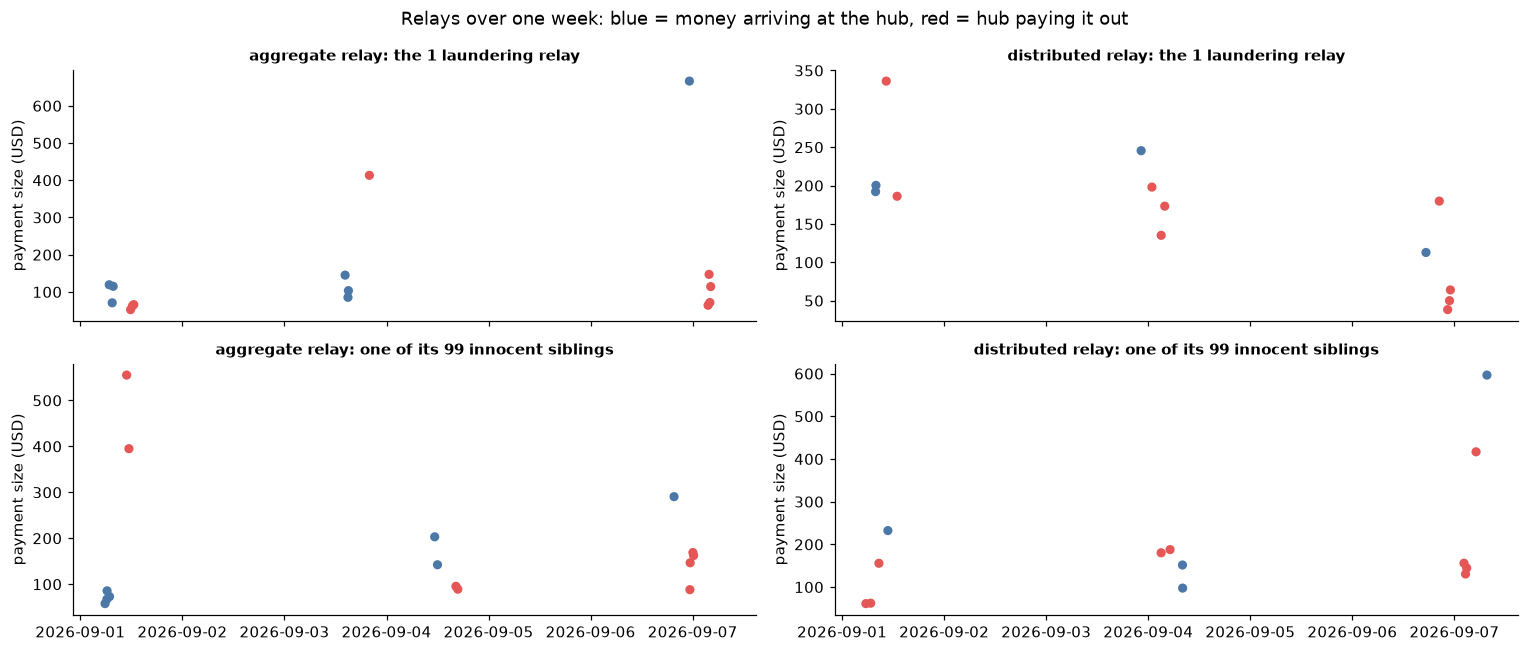

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex=True)
for j, fam in enumerate(["aggregate_relay", "distributed_relay"]):
    sus = pay[(pay.family == fam) & (pay.is_suspicious == 1)]
    sid, cohort = sus.scenario_id.iloc[0], sus.cohort_id.iloc[0]
    decoy = pay[(pay.cohort_id == cohort) & (pay.is_suspicious == 0)].scenario_id.iloc[0]
    for i, (s, name) in enumerate([(sid, "the 1 laundering relay"), (decoy, "one of its 99 innocent siblings")]):
        d = pay[pay.scenario_id == s].sort_values("t")
        hub = set(d.sender) & set(d.receiver)
        colour = np.where(d.sender.isin(hub), RED, BLUE)
        axes[i, j].scatter(pd.to_datetime(d.t, unit="s"), d.dlv_usd, c=colour, s=25)
        axes[i, j].set_title(f"{fam.replace('_', ' ')}: {name}", fontsize=10)
        axes[i, j].set_ylabel("payment size (USD)")
plt.suptitle("Relays over one week: blue = money arriving at the hub, red = hub paying it out", fontsize=12)
plt.tight_layout(); plt.show()

**How to read this chart:** each dot is one payment over the week. Blue dots are money arriving at a relay "hub" account; red dots are the hub sending it on. Money arrives in waves 1–2 days apart.

**Takeaway:** the laundering relay (top) and its innocent sibling (bottom) look almost identical. That is why these "hard" cases are so difficult: the clues are tiny (the laundering one forwards a little faster, or moves bigger and more uneven amounts) and only visible when compared with the other 99 siblings.

### 3b. Speed, value kept and routes

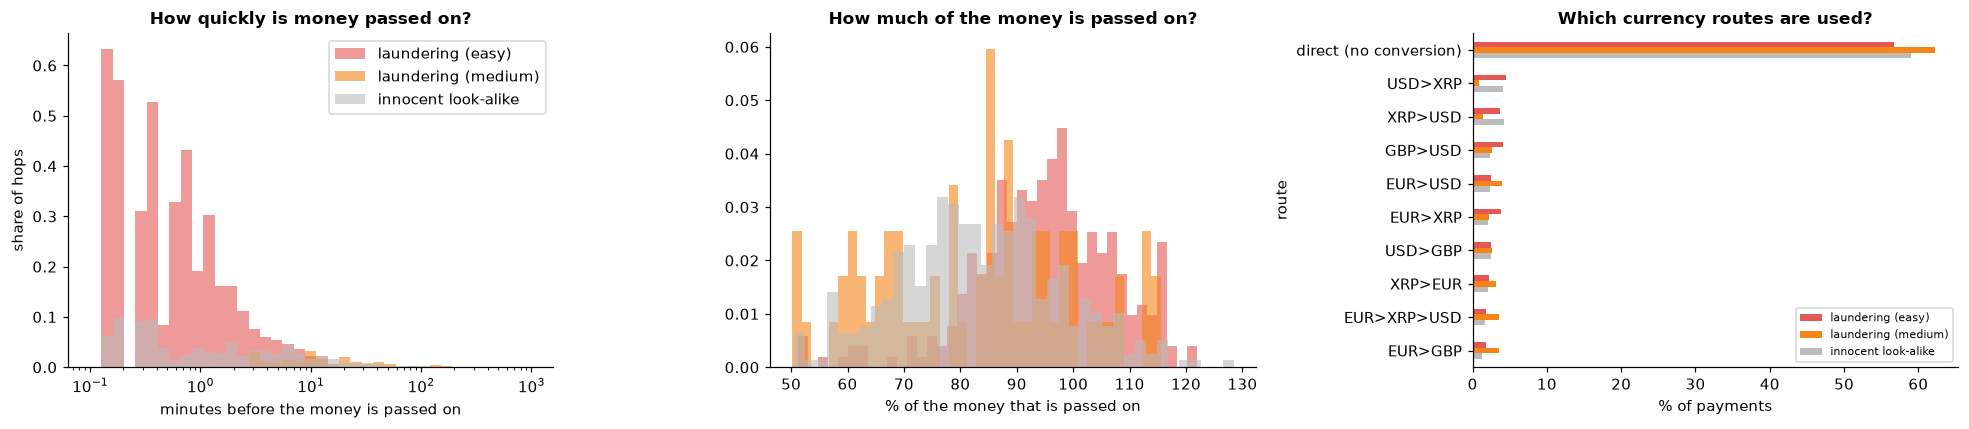

In [5]:
def hop_table(df):
    rows = []
    for sid, d in df[df.scenario_id.notna()].groupby("scenario_id"):
        d = d.sort_values("t")
        for r in d.itertuples():
            p = d[(d.receiver == r.sender) & (d.t <= r.t)]
            if len(p):
                rows.append((r.family, r.difficulty, r.t - p.t.iloc[-1], r.dlv_usd / p.dlv_usd.iloc[-1]))
    return pd.DataFrame(rows, columns=["family", "difficulty", "delay_s", "retention"])

hops = hop_table(pay[~pay.family.isin(["aggregate_relay", "distributed_relay"])])
labels_ = {"easy": "laundering (easy)", "medium": "laundering (medium)", "normal": "innocent look-alike"}
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for diff, c in [("easy", RED), ("medium", ORANGE), ("normal", GREY)]:
    h = hops[hops.difficulty == diff]
    ax[0].hist(h.delay_s / 60, bins=np.logspace(-1, 3, 40), alpha=0.6, color=c, label=labels_[diff], density=True)
ax[0].set_xscale("log"); ax[0].set_xlabel("minutes before the money is passed on"); ax[0].set_ylabel("share of hops")
ax[0].set_title("How quickly is money passed on?"); ax[0].legend()
for diff, c in [("easy", RED), ("medium", ORANGE), ("normal", GREY)]:
    h = hops[(hops.difficulty == diff) & hops.retention.between(0.5, 1.3)]
    ax[1].hist(h.retention * 100, bins=40, alpha=0.6, color=c, density=True, label=labels_[diff])
ax[1].set_xlabel("% of the money that is passed on"); ax[1].set_title("How much of the money is passed on?")
route = pay.route.where(pay.n_legs > 1, "direct (no conversion)")
ct = 100 * pd.crosstab(route, pay.difficulty.map(labels_), normalize="columns")
ct = ct.loc[ct.mean(axis=1).sort_values(ascending=False).index[:10], [labels_["easy"], labels_["medium"], labels_["normal"]]]
ct.plot.barh(ax=ax[2], color=[RED, ORANGE, GREY]); ax[2].invert_yaxis()
ax[2].set_xlabel("% of payments"); ax[2].set_title("Which currency routes are used?"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

**How to read these charts:**
- **Left:** how many minutes an account waits before passing money on (log scale: each tick is 10× longer). Red (easy laundering) sits at about a minute. Orange (medium) and grey (innocent) sit at tens of minutes to hours.
- **Middle:** what share of the money is passed on. Laundering bunches near 95–100%, so the money goes straight through. Innocent look-alikes lose more along the way.
- **Right:** which currency routes payments take. The bars have the same length for every group, so routes do not give laundering away.

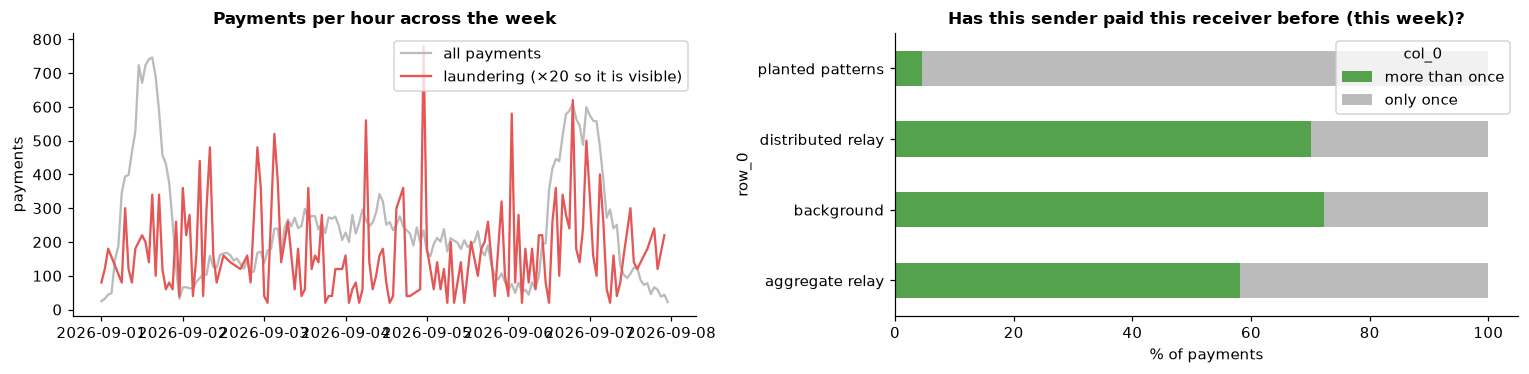

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ts = pd.to_datetime(pay.t, unit="s").dt.floor("h")
ax[0].plot(ts.value_counts().sort_index(), color=GREY, label="all payments")
ax[0].plot(ts[pay.is_suspicious == 1].value_counts().sort_index() * 20, color=RED, label="laundering (×20 so it is visible)")
ax[0].legend(); ax[0].set_title("Payments per hour across the week"); ax[0].set_ylabel("payments")
pc = (pay.sender + ">" + pay.receiver).map((pay.sender + ">" + pay.receiver).value_counts())
grp = np.where(pay.family.isin(["background", "aggregate_relay", "distributed_relay"]), pay.family.str.replace("_", " "), "planted patterns")
tab = 100 * pd.crosstab(grp, np.where(pc == 1, "only once", "more than once"), normalize="index")
tab.plot.barh(stacked=True, ax=ax[1], color=[GREEN, GREY])
ax[1].set_xlabel("% of payments"); ax[1].set_title("Has this sender paid this receiver before (this week)?")
plt.tight_layout(); plt.show()

**How to read these charts:**
- **Left:** grey shows normal traffic per hour; red shows laundering, scaled up 20× so you can see it. Laundering is spread across the whole week, so the time of day or week doesn't give it away.
- **Right:** green is the share of payments between two accounts that never transact again that week. Planted patterns, whether laundering or look-alike, almost always use brand-new pairs. Normal background commerce mostly repeats the same pairs.

That makes "brand-new pair" a strong filter for *planted pattern vs everyday activity*.

## 4. Describe every payment with numbers (feature matrix)

| Feature family | What it measures, in plain words |
|---|---|
| Direct vs path ratios | How often an account converts currency instead of paying directly, over 10 min to 1 day |
| Slippage / SendMax | Gap between the "at most I'll pay" ceiling, the real cost and the delivered amount (no signal: always 1.01×) |
| Round-trip / circular | Does money come back to where it started? **v8:** checked across the whole reconstructed flow, not just 10 minutes |
| Issuer hopping | Switching between the same currency from different issuers |
| Fan-in / fan-out velocity | How many different accounts pay in, and are paid out, in a short window |
| Account age & bursts | A brand-new account suddenly sending many payments |
| Bridge dependency | How often payments are routed through XRP between two other currencies |
| Value preservation | How much of the money survives each step |
| Pass-through timing | How fast the receiver passes the money on |
| Topology mix | Payments are grouped into "flows"; we count how many fan-in, fan-out and chain accounts each flow mixes |
| Amount-matched flows | Slow flows rebuilt by linking each payment to the earlier payment of the closest amount |
| **v8 Scenario aggregates** (`scn*`) | For each payment, statistics of its **whole reconstructed scenario**: average speed, average value kept, how regular the timing is (gap variation), the payment's size relative to the scenario average |
| **v8 Graph-size normalised** (`norm*`) | Counts divided by flow size: share of accounts that are fan-out/fan-in/chain, payments per account, seconds and dollars per payment |
| **v8 Relay hub scenario** (`hubscn*`) | Each account's *recurring* links over the week (relay-like), described as a whole: total, largest, unevenness and hold time, ranked against hubs of the same size (a stand-in for the relay cohort) |
| **v9 Wider medium grouping** (`mflowC*`) | Amount-matched flows with 4h hops and 60-min fan siblings: recovers about half of each medium scenario (v8's grouping: about a quarter) |
| **v9 Shape-relative scenarios** (`shp*`) | Each scenario's duration, gaps, total and largest money, % passed on and conversion mix, **ranked against scenarios of the same shape** in the same split; "slow + rich" score; % passed on only for chain-like flows |
| **v9 Blob fix** | Every component / scenario feature is blanked when its component has more than 40 payments |
| Base rules | The rules in the table at the top, as yes/no flags |

In [7]:
%%time
X_raw, comps = af.build_features(pay, verbose=False)
Xt_raw, test_comps = af.build_features(test_pay, verbose=False)
with_rules = lambda X: pd.concat([X, af.rule_flags(X)], axis=1)
X_all, Xt_all = with_rules(X_raw), with_rules(Xt_raw)

# Cleanup carried over from v7: drop the 30 features the ensemble used least (constant columns, the
# short-window round-trip family, single-payment flags covered by flow features, weak rule flags).
# The rule flags stay in X_all so section 6 can still evaluate every base rule.
DROP_FEATURES = ['R12_meaningless_roundtrip_asset', 'R08_round_trip', 'is_path_payment', 'R13_sendmax_slack', 'cmpF1h_fresh_pair_frac', 'round_trip_len_1h', 'round_trip_10m', 'meaningless_roundtrip_asset', 'round_trip_len_10m', 'cmpF4h_fresh_pair_frac', 'round_trip_1h', 'R14_new_account_burst', 'mflowA_closes_loop', 'is_xrp_bridge', 'cmp5m_closes_loop', 'rcv_fwd_cnt_10m', 'usd_cents_round', 'mflowA_hop_fast3m_share', 'mflowB_closes_loop', 'R11_issuer_hop', 'chain_fwd_10m', 'R10_relay_largest_payment', 'mflowA_position', 'cmpF4h_fan_out_nodes', 'R06_slow_flow_high_retention', 'n_legs', 'sen_days_out', 'cmpF1h_closes_loop', 'mflowA_n_tx', 'mflowB_position']
# v10: per-account weekly "fingerprint" features that make train and test perfectly separable (section 4b).
ACCOUNT_FINGERPRINTS = ['snd_week_path_ratio', 'hubscn_sen_usd_cv', 'snd_week_lp_per_tx', 'sen_week_net_flow', 'shp5m_shape_count', 'snd_path_ratio_1440m', 'rec_week_net_flow', 'hubscn_rec_usd_cv', 'rcv_week_recvs', 'hubscn_sen_usd_in', 'snd_week_bridge_ratio', 'sen_dwell_p90', 'sen_dwell_med', 'sen_week_in_usd', 'hubscn_sen_usd_max', 'rec_week_in_usd', 'rcv_in_pairs_recurring_frac', 'hubscn_rec_usd_in', 'hubscn_rec_usd_max', 'rec_dwell_p90', 'snd_pairs_recurring_frac', 'hubscn_sen_hold_med', 'hubscn_sen_hold_min', 'sen_week_out_usd', 'snd_week_sends', 'sen_dwell_min', 'rec_dwell_med', 'hubscn_sen_n', 'hubscn_sen_n_src', 'rec_week_out_usd', 'hubscn_rec_hold_med', 'hubscn_rec_hold_min', 'hubscn_rec_n', 'rec_dwell_min', 'hubscn_rec_n_src', 'hubscn_sen_usd_in_pct_in_size', 'hubscn_sen_hold_min_pct_in_size', 'hubscn_sen_n_dst', 'hubscn_sen_usd_cv_pct_in_size', 'hubscn_sen_usd_max_pct_in_size', 'hubscn_sen_hold_med_pct_in_size', 'hubscn_rec_usd_in_pct_in_size', 'hubscn_rec_n_dst', 'hubscn_rec_usd_max_pct_in_size', 'shp5m_conv_frac_pct_shape', 'snd_burst_vs_week', 'shp5m_route_entropy_pct_shape', 'hubscn_rec_hold_min_pct_in_size', 'hubscn_rec_usd_cv_pct_in_size', 'hubscn_rec_hold_med_pct_in_size', 'snd_path_ratio_360m', 'shpmflowB_shape_count', 'hubscn_sen_waves', 'shpmflowC_shape_count', 'sen_out_waves', 'snd_bridge_ratio_1440m', 'hubscn_rec_waves', 'shpmflowC_conv_frac_pct_shape', 'pair_week_days', 'value_vs_sender_median']
FEATURES = [c for c in X_all.columns if c != "TRANSACTION_HASH" and c not in DROP_FEATURES and c not in ACCOUNT_FINGERPRINTS]
# v10: the robust core: short-window flow features only (5-min bursts, pass-through, chains, base rules)
CORE_PREFIXES = ("cmp5m_", "scn5m_", "norm5m_", "shp5m_", "chain_", "rcv_next_send", "rcv_similar_fwd", "rcv_passthrough",
                 "snd_prev_recv", "snd_inflow", "min_hop_delay", "log_rcv_next", "log_snd_prev", "R0", "R1", "value_retention",
                 "conversion_cost", "fee_drops", "n_issuers", "issuer_hop", "delivers_xrp", "is_xrp_bridge", "n_legs", "log_usd")
CORE = [c for c in FEATURES if c.startswith(CORE_PREFIXES) or c.endswith(("_10m", "_60m"))]
X, Xt = X_all[FEATURES], Xt_all[FEATURES]
y = pay.set_index("TRANSACTION_HASH").loc[X_all.TRANSACTION_HASH, "is_suspicious"].to_numpy().astype(int)
meta = pay.set_index("TRANSACTION_HASH").loc[X_all.TRANSACTION_HASH, ["family", "difficulty", "scenario_id", "cohort_id"]].reset_index()
groups_of = pd.Series({c: af.feature_group(c) for c in FEATURES})
print(f"{X.shape[1]} features for {X.shape[0]:,} training payments ({len(DROP_FEATURES)} dropped as dead weight, "
      f"{len(ACCOUNT_FINGERPRINTS)} dropped as account fingerprints); robust core model uses {len(CORE)}")
groups_of.value_counts().rename("features per family").to_frame()

430 features for 40,131 training payments (30 dropped as dead weight, 60 dropped as account fingerprints); robust core model uses 126
CPU times: user 1min 3s, sys: 303 ms, total: 1min 3s
Wall time: 1min 3s


,features per family
Shape-relative scenarios,82
Scenario aggregates,60
Transaction basics,56
Topology mix (components),56
Fan-in / fan-out velocity,45
Graph-size normalised,38
Pass-through timing,28
Value preservation,14
Relay / weekly hub,10
Bridge dependency,8


### 4b. Do the features look the same in train and test? (adversarial validation)
We train a model to guess whether a payment comes from **train** or **test**. No laundering labels are used. If it can tell them apart easily, the features describe something that differs between the two, such as particular accounts or the way a batch was generated, and a laundering model built on them will not carry over to the leaderboard.

**How to read the result:** 0.5 means train and test look the same (good); 1.0 means they are completely different.

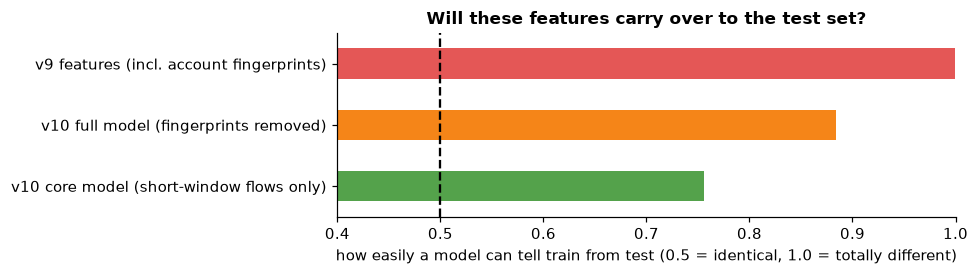

examples of removed account fingerprints: ['snd_week_path_ratio', 'hubscn_sen_usd_cv', 'snd_week_lp_per_tx', 'sen_week_net_flow', 'shp5m_shape_count', 'snd_path_ratio_1440m', 'rec_week_net_flow', 'hubscn_rec_usd_cv']


In [8]:
from sklearn.model_selection import StratifiedKFold
def separability(cols):
    Z = pd.concat([X_all[cols], Xt_all[cols]], ignore_index=True)
    z = np.r_[np.zeros(len(X_all)), np.ones(len(Xt_all))]
    o = np.zeros(len(z))
    for a, b in StratifiedKFold(3, shuffle=True, random_state=0).split(Z, z):
        m = lgb.train(dict(objective="binary", learning_rate=0.1, num_leaves=31, verbose=-1, num_threads=8, seed=0), lgb.Dataset(Z.iloc[a], z[a]), 150)
        o[b] = m.predict(Z.iloc[b])
    return roc_auc_score(z, o)

ALL_BEFORE = [c for c in X_all.columns if c != "TRANSACTION_HASH" and c not in DROP_FEATURES]
sep = pd.Series({"v9 features (incl. account fingerprints)": separability(ALL_BEFORE),
                 "v10 full model (fingerprints removed)": separability(FEATURES),
                 "v10 core model (short-window flows only)": separability(CORE)})
ax = sep.plot.barh(color=[RED, ORANGE, GREEN], figsize=(9, 2.6)); ax.axvline(0.5, color="k", ls="--")
ax.set_xlim(0.4, 1.0); ax.set_xlabel("how easily a model can tell train from test (0.5 = identical, 1.0 = totally different)")
ax.set_title("Will these features carry over to the test set?"); ax.invert_yaxis(); plt.tight_layout(); plt.show()
print("examples of removed account fingerprints:", ACCOUNT_FINGERPRINTS[:8])

**How to read this chart:** shorter bars are better: they mean the features behave the same way on test as on train. The v9 features (red) let a model tell the two apart almost perfectly, which is the hidden reason v8 and v9 lost precision on the leaderboard. Removing the account fingerprints (orange) helps. The core model's short-window features (green) are the most test-like, which is why v10 blends them in.

## 5. Train and test the model

### 5a. A fair test: are we testing on scenarios the model has never seen?
All payments from one scenario go into the **same** test fold (`StratifiedGroupKFold`, grouped by scenario). If we split payment by payment instead, the model would see half of a scenario during training and "recognise" the other half, which is cheating. Test wallets are completely new, so this grouped test is the honest one. The check below proves no scenario is split.

In [9]:
groups = meta.scenario_id.fillna(meta.TRANSACTION_HASH).to_numpy()
FOLDS = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, y, groups))
fold_of = np.empty(len(y), int)
for k, (_, check_rows) in enumerate(FOLDS):
    fold_of[check_rows] = k
split = pd.Series(fold_of).groupby(meta.scenario_id.to_numpy()).nunique()
print(f"scenarios that appear in more than one fold: {(split > 1).sum()} of {len(split)}  -> grouping is correct")
pd.DataFrame({"fold": range(5), "payments": [len(c) for _, c in FOLDS],
              "laundering payments": [int(y[c].sum()) for _, c in FOLDS]}).set_index("fold").T

scenarios that appear in more than one fold: 0 of 1497  -> grouping is correct


fold,0,1,2,3,4
payments,8027,8026,8026,8026,8026
laundering payments,250,250,250,250,250


### 5b. Hyperparameters: what we tried

You asked us to loosen the regularisation so the trees could learn harder patterns. We tested this properly. We ran a random search of 18 settings plus "31 leaves, L2 = 1", each scored with the grouped 5-fold test (binary log-loss, v8 features).

| Tree size | Grouped CV AP (range over settings) |
|---|---|
| **15 leaves** | **55.7 – 56.3** |
| 31 leaves (incl. L2 = 1, min leaf 20) | 54.9 – 55.5 |
| 63 leaves | 54.6 – 55.2 |

**Result:** bigger, less-regularised trees were worse every time. There are only ~300 laundering scenarios. Big trees memorise individual scenarios ("this exact flow was guilty") instead of learning patterns that carry over to new wallets. L2 strength made almost no difference. The winning setting does loosen two things: leaves may hold 30 payments instead of 50, and each tree sees 90% of the features instead of 70%. It also learns faster (0.05) with fewer rounds (400).

**v9 experiments.** Each is the average of 3 different grouped 5-fold splits (single LightGBM, binary loss). "Easy guard" = easy-case AP must not drop.

| v9 step | Overall AP | Easy | Medium | Top-1% precision | Kept? |
|---|---|---|---|---|---|
| v8 features (reference) | 56.7 | 0.766 | 0.071 | 81.7% | n/a |
| + blob fix | 57.0 | 0.767 | 0.082 | 82.4% | ✅ |
| + shape-relative medium features + wider medium grouping | 56.8 | 0.769 | 0.067 | 83.8% | ✅ (best top-1%) |
| only the 17 strongest shape features | 56.3 | 0.762 | 0.079 | 81.9% | ❌ |
| + medium specialist model blended in (α = 0.1) | 45.2 | 0.567 | 0.056 | 65.8% | ❌ wrecks easy cases |
| + ambiguous payments weight 0 | 56.8 | 0.766 | 0.084 | 82.4% | ✅ (principled, neutral) |

**Shape-relative features do separate medium cases from look-alikes:** the gap between payments ranked within the same shape reaches AUC 0.77, against at most 0.56 for any single-payment feature before. But medium payments are only 0.6% of the data, so the overall score barely moves.

**Relay rebuild (rejected).** (1) Splitting each hub's activity into time waves: hubs receive almost continuously, so purity was only 41%. (2) Linking counterparties that deal with the hub in the same hour on 2+ days: it covered more background commerce (57%) than relay payments (41%), at 67% purity. Stricter settings reached 80–92% purity but recovered only 3–13% of each relay. Recurring normal commerce looks exactly like a relay's repeated counterparties, and each hub is shared by ~3 scenarios.

Two more v8 ideas were tested and **rejected**:

| Idea | Grouped CV AP | Why rejected |
|---|---|---|
| Up-weight medium/hard laundering ×3 to ×10 | 53.8 – 54.7 (vs 56.3) | Easy cases lose more than medium/hard gain: those still can't be told apart from their look-alikes |
| Boost the top-50 features ×1.5 (`feature_contri`) | 60.1 vs 60.6 (ensemble) | Looked like +1.0 until the top-50 list was chosen inside each training fold; the gain was leakage |

In [10]:
PARAMS = dict(learning_rate=0.05, num_leaves=15, min_data_in_leaf=30, feature_fraction=0.9,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, min_gain_to_split=0.01,
              num_threads=8, seed=0, deterministic=True, force_col_wise=True, verbose=-1)
ROUNDS = 400

def focal_objective(gamma=2.0, alpha=0.25):
    # Focal loss (Lin et al. 2017) gradient w.r.t. the raw score; hessian by central difference.
    def grad(z, y):
        p = np.clip(1 / (1 + np.exp(-z)), 1e-7, 1 - 1e-7)
        g1 = alpha * (1 - p) ** gamma * (gamma * p * np.log(p) + p - 1)
        g0 = (1 - alpha) * p ** gamma * (p - gamma * (1 - p) * np.log(1 - p))
        return np.where(y == 1, g1, g0)
    def obj(z, data):
        yy = data.get_label()
        h = (grad(z + 1e-3, yy) - grad(z - 1e-3, yy)) / 2e-3
        return grad(z, yy), np.maximum(h, 1e-6)
    return obj

LOSSES = {
    "binary log-loss": dict(objective="binary"),
    "weighted binary": dict(objective="binary", scale_pos_weight=10),
    "focal loss": dict(objective=focal_objective()),
    "rank_xendcg": dict(objective="rank_xendcg"),
}

# v9: the 25 ambiguous payments have random labels by design -> zero training weight (still scored).
TRAIN_WEIGHT = pd.Series(np.where(meta.family.to_numpy() == "ambiguous", 0.0, 1.0), index=X.index)

def fit(loss, X_fit, y_fit, seed=0):
    params = dict(PARAMS, seed=seed, **LOSSES[loss])
    if loss == "rank_xendcg":   # ranking needs query groups: random chunks of 1,000 payments
        order = np.random.default_rng(seed).permutation(len(y_fit))
        X_fit, y_fit = X_fit.iloc[order], y_fit[order]
        sizes = [1000] * (len(y_fit) // 1000) + ([len(y_fit) % 1000] if len(y_fit) % 1000 else [])
        return lgb.train(params, lgb.Dataset(X_fit, y_fit, group=sizes, weight=TRAIN_WEIGHT.loc[X_fit.index].to_numpy()), ROUNDS)
    return lgb.train(params, lgb.Dataset(X_fit, y_fit, weight=TRAIN_WEIGHT.loc[X_fit.index].to_numpy()), ROUNDS)

diff = meta.difficulty.to_numpy()
is_relay = meta.family.str.contains("relay").to_numpy()

def evaluate(score):
    out = {"AP (site score)": average_precision_score(y, score), "ROC AUC": roc_auc_score(y, score)}
    for d in ["easy", "medium", "hard"]:
        m = (y == 0) | (diff == d)
        out[f"AP {d}"] = average_precision_score(y[m], score[m])
    m = (y == 0) | is_relay
    out["AP relays"] = average_precision_score(y[m], score[m])
    top = np.argsort(-score)[: int(0.01 * len(y))]
    out["precision@1%"], out["recall@1%"] = y[top].mean(), y[top].sum() / y.sum()
    out["AP fold std"] = np.std([average_precision_score(y[c], score[c]) for _, c in FOLDS])
    return out

### 5c. Which loss function?

The loss function is what the trees try to minimise while learning. We compare four on the same grouped test:

| Loss | Idea |
|---|---|
| **Binary log-loss** | Standard "predict the probability of laundering" |
| Weighted binary | Same, but each laundering payment counts 10× |
| Focal loss | Pays less attention to examples that are already easy |
| `rank_xendcg` | Learns the *ordering* directly, which is what AP rewards |

In [11]:
%%time
oof, models = {}, {}
for loss in LOSSES:
    o = np.zeros(len(y))
    for fit_rows, check_rows in FOLDS:
        m = fit(loss, X.iloc[fit_rows], y[fit_rows])
        o[check_rows] = m.predict(X.iloc[check_rows], raw_score=True)
        models.setdefault(loss, []).append(m)
    oof[loss] = o
cv = pd.DataFrame({loss: evaluate(o) for loss, o in oof.items()}).T
cv.round(3)

CPU times: user 2min 50s, sys: 28.5 s, total: 3min 18s
Wall time: 45 s


,AP (site score),ROC AUC,AP easy,AP medium,AP hard,AP relays,precision@1%,recall@1%,AP fold std
binary log-loss,0.553,0.892,0.760,0.068,0.008,0.007,0.800,0.257,0.040
weighted binary,0.534,0.887,0.738,0.033,0.007,0.007,0.805,0.258,0.041
focal loss,0.550,0.887,0.753,0.045,0.007,0.007,0.800,0.257,0.023
rank_xendcg,0.567,0.892,0.772,0.049,0.007,0.006,0.796,0.255,0.060


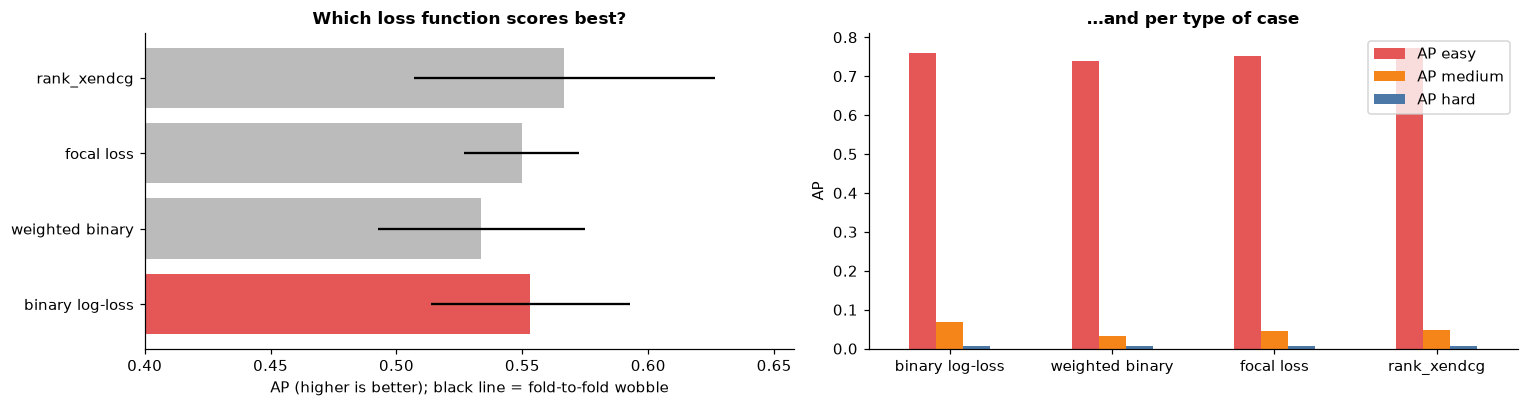


> ### ⭐ Selected loss function: **binary log-loss**
> Grouped 5-fold AP = **0.553** (± 0.040). Losses within one fold-std of the best (binary log-loss, weighted binary, focal loss, rank_xendcg) are statistically tied.
> Binary log-loss is preferred among tied losses: it outputs a calibrated probability in [0, 1], which is exactly the "1 = suspicious, 0 = clear" label required.
> The final model (section 7) **averages the rankings of binary log-loss and `rank_xendcg`**, because the two make different mistakes.

**How to read this chart:** the left bars are the overall score for each loss; the thin black line on each bar is how much that score wobbles between folds. Overlapping wobbles mean "no real difference". The right chart splits the score by case type. Easy cases score high, and medium and hard stay near the floor whichever loss is used.


In [12]:
best_ap = cv["AP (site score)"].max()
tol = cv.loc[cv["AP (site score)"].idxmax(), "AP fold std"]
tied = cv.index[cv["AP (site score)"] >= best_ap - tol].tolist()
BEST_LOSS = "binary log-loss" if "binary log-loss" in tied else cv["AP (site score)"].idxmax()

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].barh(cv.index, cv["AP (site score)"], xerr=cv["AP fold std"], color=[RED if l == BEST_LOSS else GREY for l in cv.index])
ax[0].set_xlim(0.4, None); ax[0].set_xlabel("AP (higher is better); black line = fold-to-fold wobble")
ax[0].set_title("Which loss function scores best?")
cv[["AP easy", "AP medium", "AP hard"]].plot.bar(ax=ax[1], rot=0, color=[RED, ORANGE, BLUE])
ax[1].set_title("…and per type of case"); ax[1].set_ylabel("AP")
plt.tight_layout(); plt.show()
display(Markdown(f'''
> ### ⭐ Selected loss function: **{BEST_LOSS}**
> Grouped 5-fold AP = **{cv.loc[BEST_LOSS, "AP (site score)"]:.3f}** (± {cv.loc[BEST_LOSS, "AP fold std"]:.3f}). Losses within one fold-std of the best ({", ".join(tied)}) are statistically tied.
> Binary log-loss is preferred among tied losses: it outputs a calibrated probability in [0, 1], which is exactly the "1 = suspicious, 0 = clear" label required.
> The final model (section 7) **averages the rankings of binary log-loss and `rank_xendcg`**, because the two make different mistakes.

**How to read this chart:** the left bars are the overall score for each loss; the thin black line on each bar is how much that score wobbles between folds. Overlapping wobbles mean "no real difference". The right chart splits the score by case type. Easy cases score high, and medium and hard stay near the floor whichever loss is used.
'''))

## 6. Diagnose: what works, what doesn't, and where the model fails
### 6a. Where are the laundering payments in our ranked list?

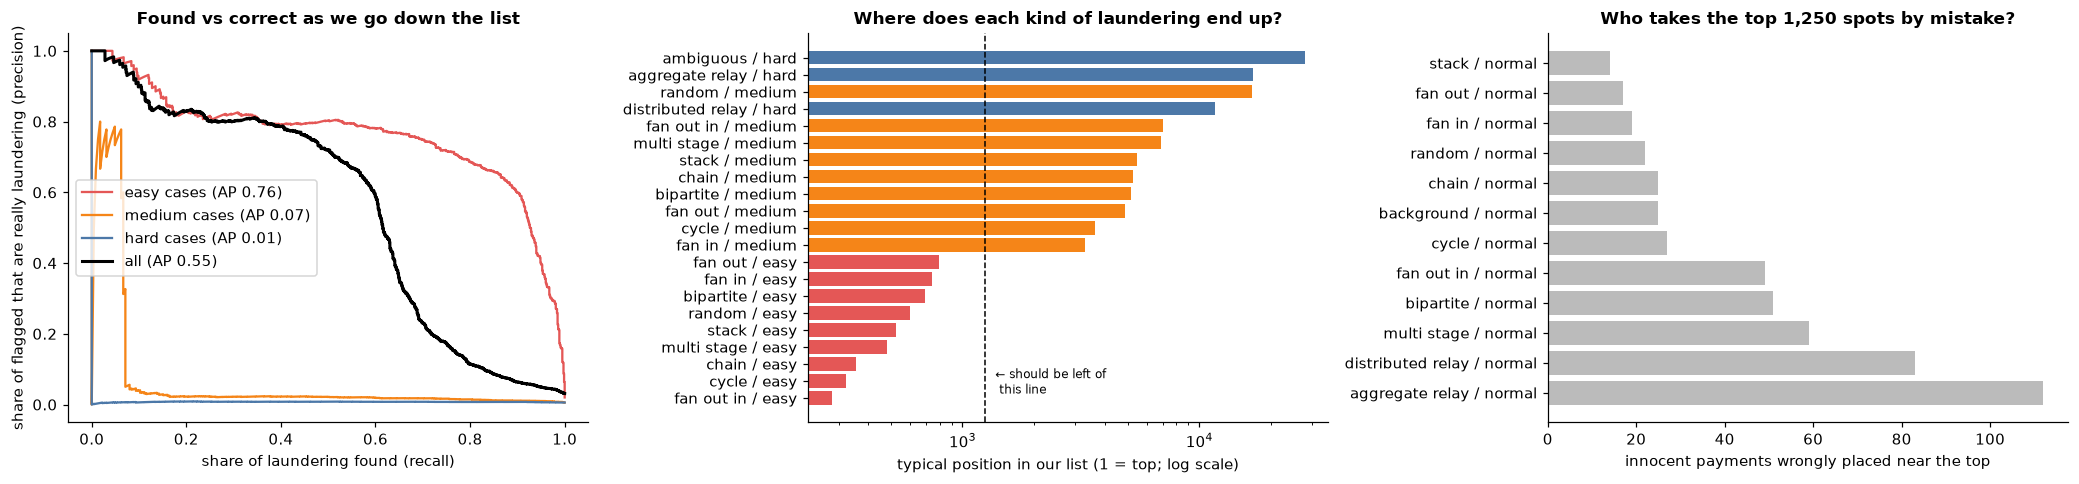

In [13]:
score = oof[BEST_LOSS]
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
for d, c in [("easy", RED), ("medium", ORANGE), ("hard", BLUE)]:
    m = (y == 0) | (diff == d)
    p, r, _ = precision_recall_curve(y[m], score[m]); ax[0].plot(r, p, color=c, label=f"{d} cases (AP {average_precision_score(y[m], score[m]):.2f})")
p, r, _ = precision_recall_curve(y, score); ax[0].plot(r, p, "k", lw=2, label=f"all (AP {average_precision_score(y, score):.2f})")
ax[0].set_xlabel("share of laundering found (recall)"); ax[0].set_ylabel("share of flagged that are really laundering (precision)")
ax[0].legend(); ax[0].set_title("Found vs correct as we go down the list")

rank = pd.Series(score).rank(ascending=False).to_numpy()
lab = (meta.family.str.replace("_", " ") + " / " + meta.difficulty).to_numpy()
s = pd.DataFrame({"g": lab, "rank": rank, "y": y})
med = s[s.y == 1].groupby("g")["rank"].median().sort_values()
cols = [RED if "easy" in g else ORANGE if "medium" in g else BLUE for g in med.index]
ax[1].barh(med.index, med.values, color=cols); ax[1].axvline(y.sum(), color="k", ls="--", lw=1)
ax[1].set_xscale("log"); ax[1].set_xlabel("typical position in our list (1 = top; log scale)")
ax[1].set_title("Where does each kind of laundering end up?")
ax[1].text(y.sum() * 1.1, 0, "← should be left of\n this line", fontsize=8, va="bottom")
fp = s[(s.y == 0) & (s["rank"] <= y.sum())].g.value_counts()
ax[2].barh(fp.index, fp.values, color=GREY); ax[2].set_xlabel("innocent payments wrongly placed near the top")
ax[2].set_title(f"Who takes the top {y.sum():,} spots by mistake?")
plt.tight_layout(); plt.show()

**How to read these charts:**
- **Left:** imagine walking down our ranked list. The x-axis is how much of the laundering we have found so far; the y-axis is how many of the payments we flagged were really laundering. A perfect model would be a flat line at the top. The red (easy) line stays high for a long way. The orange (medium) and blue (hard) lines collapse almost at once: those cases are not near the top.
- **Middle:** for each kind of laundering, its typical position in our list (left = near the top = good). The dashed line marks the number of laundering payments; anything left of it is where we want it. Easy cases mostly sit left of it. Medium and hard cases sit thousands of places down.
- **Right:** the innocent payments that sneak into the top spots. Most are look-alike decoys and relay siblings, which is exactly what they were designed for.

### 6b. Which features helped and which didn't?

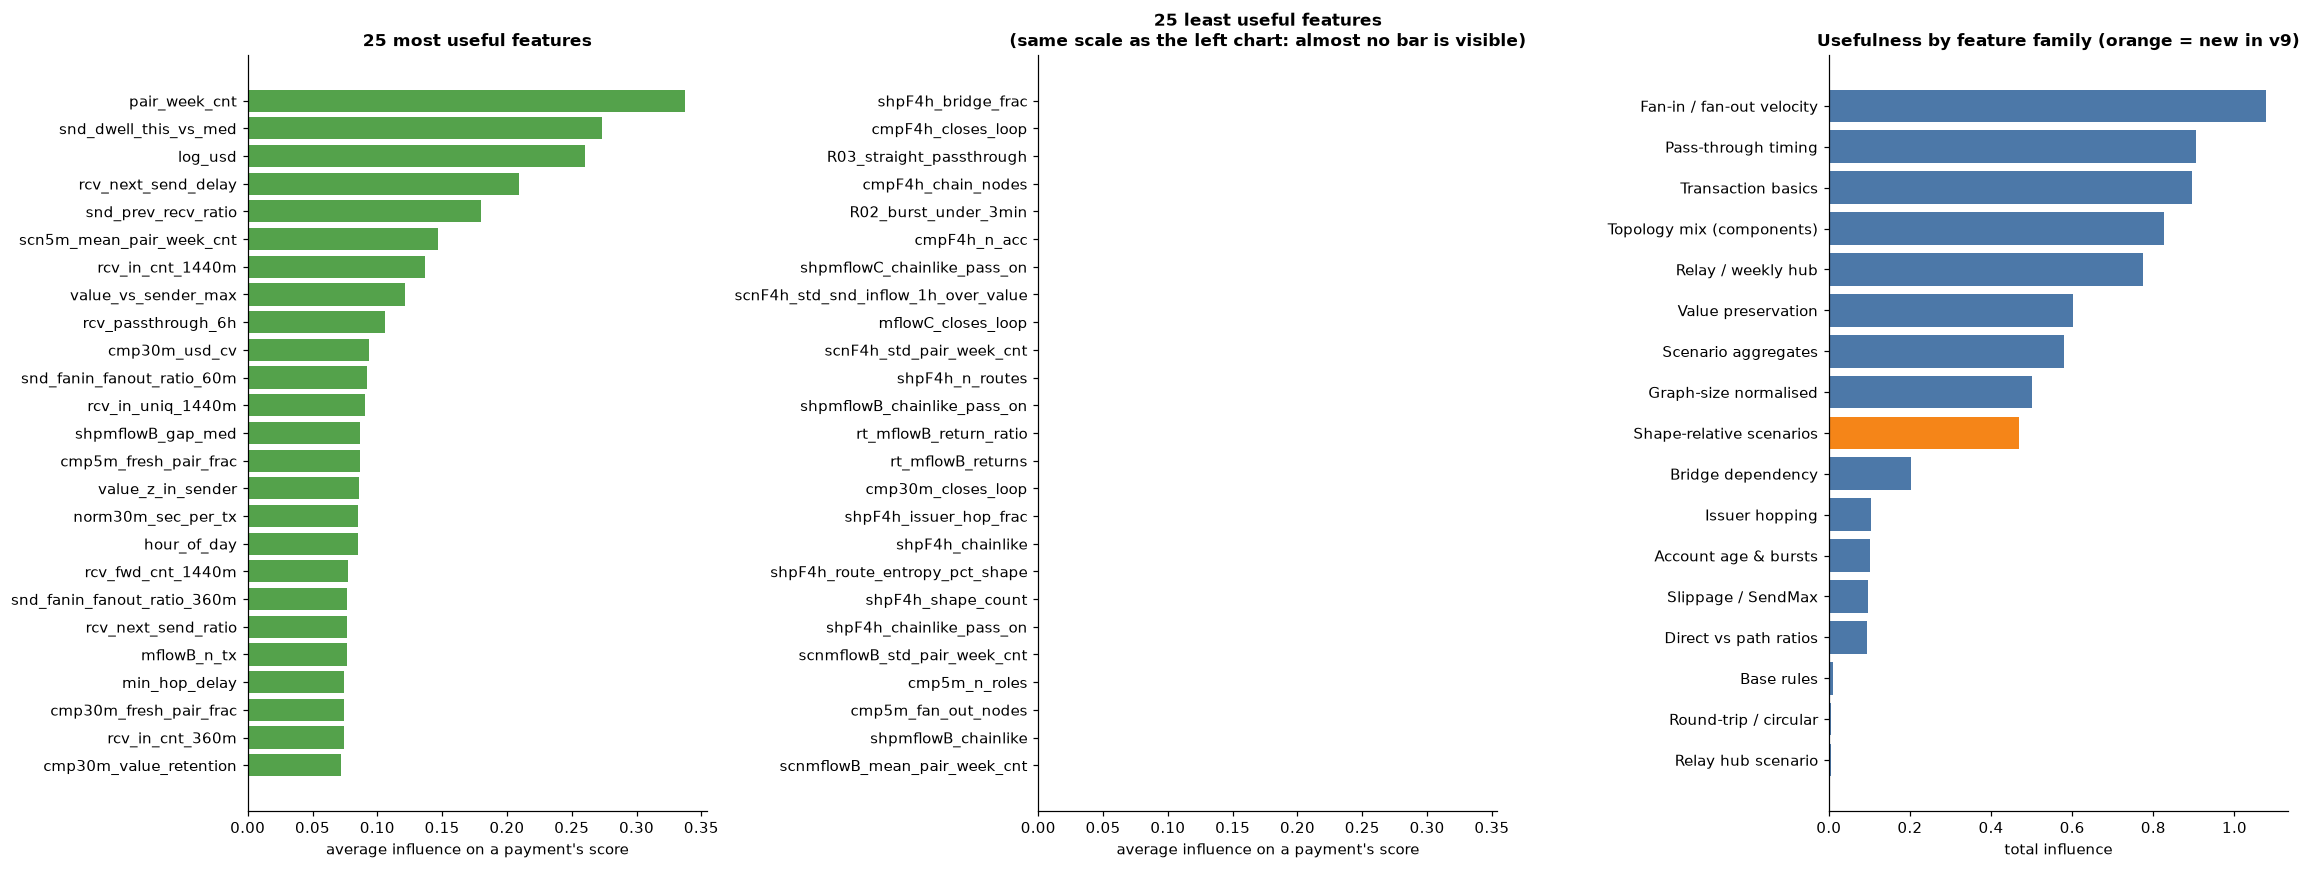

features never used by any tree: 30


In [14]:
fold_models = models[BEST_LOSS]
gain = pd.DataFrame({k: m.feature_importance("gain") for k, m in enumerate(fold_models)}, index=FEATURES).mean(axis=1)
gain = 100 * gain / gain.sum()
contrib_all = np.zeros((len(y), len(FEATURES)))
for (fit_rows, check_rows), m in zip(FOLDS, fold_models):
    contrib_all[check_rows] = m.predict(X.iloc[check_rows], pred_contrib=True)[:, :-1]
shap = pd.Series(np.abs(contrib_all).mean(0), index=FEATURES)
imp = pd.DataFrame({"gain %": gain, "mean |SHAP|": shap, "group": groups_of})

fig, ax = plt.subplots(1, 3, figsize=(21, 8))
top = imp.sort_values("mean |SHAP|", ascending=False).head(25)[::-1]
ax[0].barh(top.index, top["mean |SHAP|"], color=GREEN); ax[0].set_title("25 most useful features"); ax[0].set_xlabel("average influence on a payment's score")
bottom = imp.sort_values("mean |SHAP|").head(25)
ax[1].barh(bottom.index, bottom["mean |SHAP|"], color=GREY); ax[1].set_title("25 least useful features\n(same scale as the left chart: almost no bar is visible)")
ax[1].set_xlim(ax[0].get_xlim()); ax[1].set_xlabel("average influence on a payment's score")
grp = imp.groupby("group")["mean |SHAP|"].sum().sort_values()
ax[2].barh(grp.index, grp.values, color=[ORANGE if g in ("Shape-relative scenarios",) else BLUE for g in grp.index])
ax[2].set_title("Usefulness by feature family (orange = new in v9)"); ax[2].set_xlabel("total influence")
plt.tight_layout(); plt.show()
print("features never used by any tree:", int((gain == 0).sum()))

**How to read these charts:** "influence" (mean |SHAP|) is how far, on average, a feature pushes a payment's score up or down. Long bars mean the model leans on that feature a lot.
- **Left:** the features doing the heavy lifting: mostly flow shape, speed and "how much of the money went straight through".
- **Middle:** features that barely matter. They are candidates for removal or rework.
- **Right:** the same, added up per feature family. The orange family is new in v9; how high they sit shows how much the scenario-level view contributes.

⚠️ **"Used a lot" is not the same as "helpful".** The relay-hub features are the most-used family, yet relay cases are still ranked at chance (section 6a). The model uses them mainly to push *innocent* relay payments down, which helps the overall score but does not find the 1 guilty relay in 100.

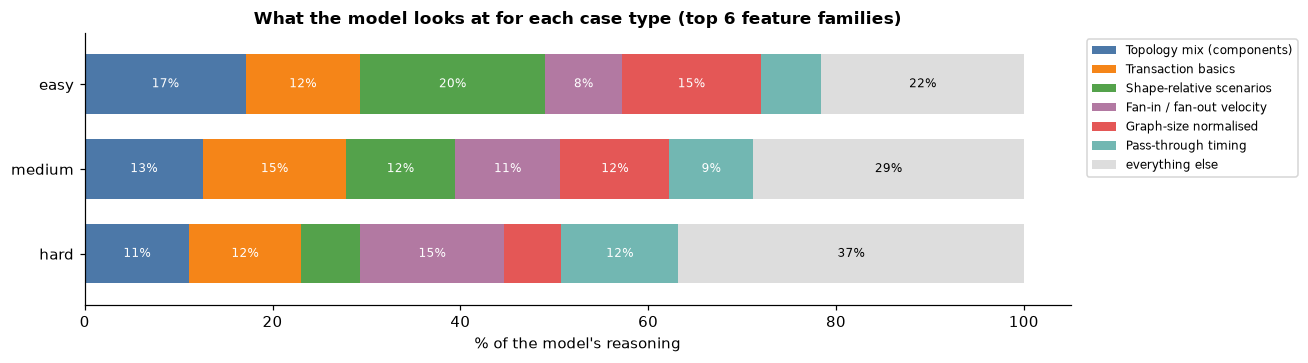

In [15]:
by_tier = pd.DataFrame({d: np.abs(contrib_all[(diff == d) & (y == 1)]).mean(0) for d in ["easy", "medium", "hard"]}, index=FEATURES)
g = by_tier.groupby(groups_of)[["easy", "medium", "hard"]].sum()
share = 100 * g / g.sum()
top6 = share.mean(axis=1).sort_values(ascending=False).index[:6]
share = pd.concat([share.loc[top6], share.drop(top6).sum().rename("everything else").to_frame().T])
palette = ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756", "#72B7B2", "#DDDDDD"]
ax = share.T.loc[["hard", "medium", "easy"]].plot.barh(stacked=True, figsize=(12, 3.4), color=palette, width=0.7)
for i, case in enumerate(["hard", "medium", "easy"]):
    left = 0
    for fam_name, v in share[case].items():
        if v >= 7:
            ax.text(left + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if fam_name != "everything else" else "black")
        left += v
ax.set_xlabel("% of the model's reasoning"); ax.set_title("What the model looks at for each case type (top 6 feature families)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8); plt.tight_layout(); plt.show()

**How to read this chart:** each bar is one case type, split into the feature families the model used to score those payments. If the medium or hard bar looks much like the easy bar, the model is judging them with the same "fast burst" logic, which is why it misses them.

### 6c. Do our hand-written base rules work?

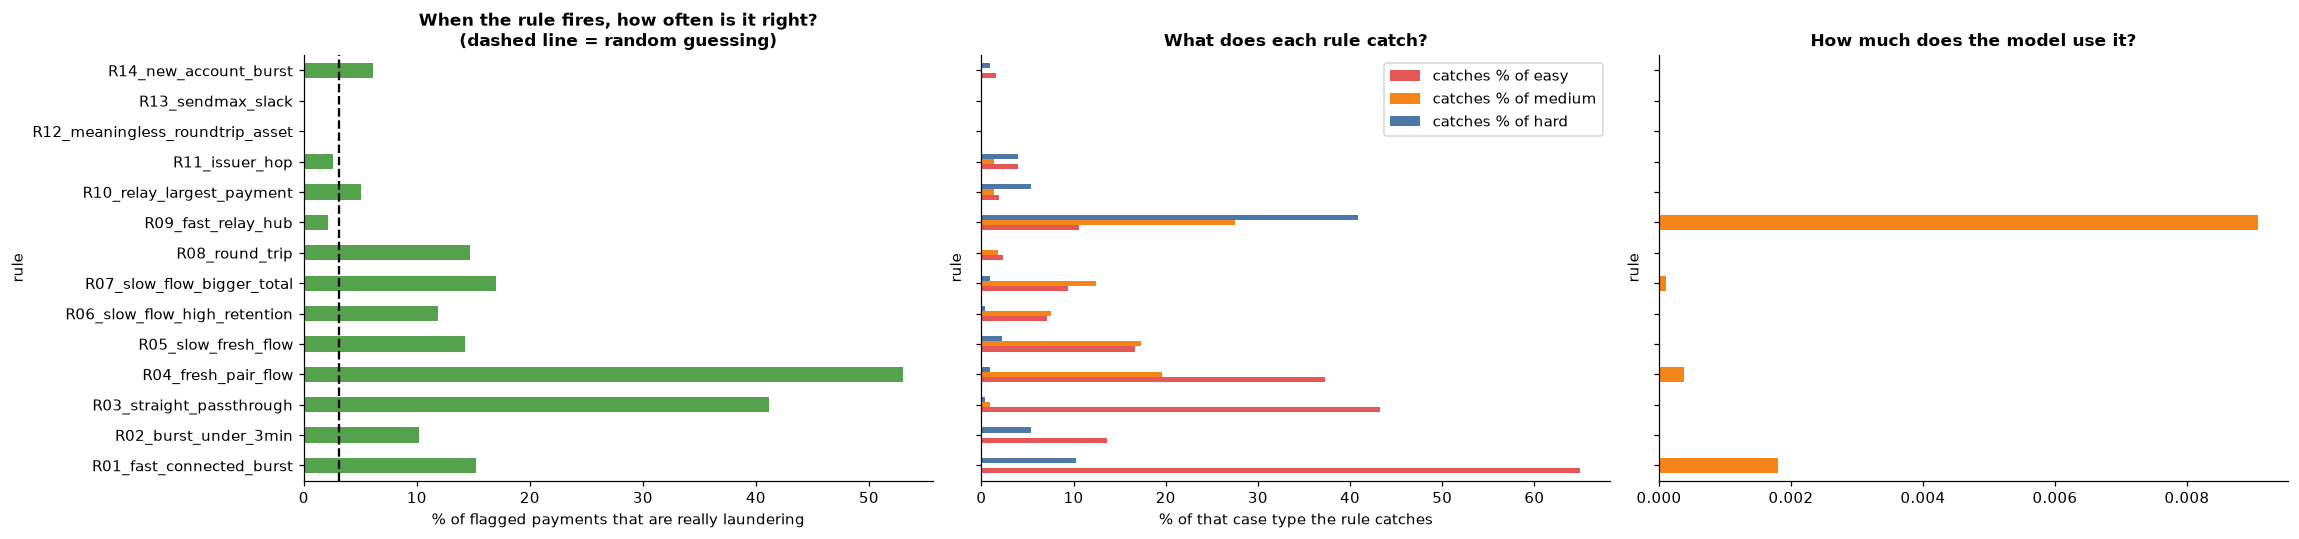

,aimed at,times it fires,precision,catches % of easy,catches % of medium,catches % of hard,false alarm on look-alikes %,model influence
rule,,,,,,,,
R01_fast_connected_burst,easy,3553,0.15,65.00,0.00,10.22,7.74,0.00
R02_burst_under_3min,easy,1186,0.10,13.62,0.00,5.33,2.74,0.00
R03_straight_passthrough,easy,847,0.41,43.25,0.89,0.44,1.28,0.00
R04_fresh_pair_flow,easy/medium,649,0.53,37.25,19.56,0.89,0.78,0.00
R05_slow_fresh_flow,medium,1238,0.14,16.62,17.33,2.22,2.73,0.00
R06_slow_flow_high_retention,medium,633,0.12,7.12,7.56,0.44,1.44,0.00
R07_slow_flow_bigger_total,medium,616,0.17,9.38,12.44,0.89,1.31,0.00
R08_round_trip,easy,156,0.15,2.38,1.78,0.00,0.34,0.00
R09_fast_relay_hub,hard (distributed relay),11040,0.02,10.62,27.56,40.89,27.78,0.01


In [16]:
rules = [c for c in X_all.columns if c[:1] == "R" and c[1:3].isdigit()]
rows = []
for r in rules:
    f = X_all[r].to_numpy() == 1
    row = {"rule": r, "aimed at": af.BASE_RULES[r][0], "times it fires": int(f.sum()),
           "precision": y[f].mean() if f.any() else np.nan}
    for d in ["easy", "medium", "hard"]:
        row[f"catches % of {d}"] = 100 * (f & (diff == d)).sum() / (diff == d).sum()
    row["false alarm on look-alikes %"] = 100 * (f & (diff == "normal")).sum() / (diff == "normal").sum()
    row["model influence"] = shap.get(r, 0.0)   # 0 = dropped as dead weight
    rows.append(row)
rule_tab = pd.DataFrame(rows).set_index("rule")

fig, ax = plt.subplots(1, 3, figsize=(21, 5))
(100 * rule_tab["precision"].fillna(0)).plot.barh(ax=ax[0], color=GREEN); ax[0].axvline(100 * y.mean(), color="k", ls="--")
ax[0].set_xlabel("% of flagged payments that are really laundering"); ax[0].set_title("When the rule fires, how often is it right?\n(dashed line = random guessing)")
rule_tab[["catches % of easy", "catches % of medium", "catches % of hard"]].plot.barh(ax=ax[1], color=[RED, ORANGE, BLUE])
ax[1].set_xlabel("% of that case type the rule catches"); ax[1].set_title("What does each rule catch?")
rule_tab["model influence"].plot.barh(ax=ax[2], color=ORANGE); ax[2].set_title("How much does the model use it?")
for a in ax[1:]: a.set_yticklabels([])
plt.tight_layout(); plt.show()
rule_tab.round(2)

**How to read these charts:** one row per rule, in the same order in all three panels.
- **Left:** if we only used this rule, how often would a flagged payment really be laundering? Bars far right of the dashed line are strong rules. R03 ("money passes straight through") and R04 ("flow made of brand-new pairs") are the best.
- **Middle:** what share of each case type the rule catches. Most rules catch easy cases (red); only R04–R07 reach medium cases (orange), and the relay rules (R09/R10) fire on the hard cases (blue) but on even more innocent relays.
- **Right:** how much the model uses the rule flag. Low values are expected even for good rules: the model already sees the raw features the rules are built from, so the flag adds little new.

## 7. Final model and the submission CSV
The final score **averages two model families 50/50**. Each family is itself 6 models (binary log-loss and `rank_xendcg`, 3 seeds each): the **full** model on all stable features, and the **core** model on short-window flow features only. Different losses and seeds make different small mistakes, and averaging cancels some of them out. The result is still a number in [0, 1], where 1 = most suspicious.

In [17]:
%%time
ENSEMBLE = [("binary log-loss", s) for s in (0, 1, 2)] + [("rank_xendcg", s) for s in (0, 1, 2)]

def family_scores(X_fit, y_fit, X_new):
    parts = [rankdata(fit(loss, X_fit, y_fit, seed).predict(X_new, raw_score=True)) / len(X_new) for loss, seed in ENSEMBLE]
    return np.mean(parts, axis=0)

def ensemble_scores(X_fit, y_fit, X_new):
    # v10: 50/50 average of the full model's ranking and the robust core model's ranking
    full = family_scores(X_fit, y_fit, X_new)
    core = family_scores(X_fit[CORE], y_fit, X_new[CORE])
    return 0.5 * rankdata(full) / len(full) + 0.5 * rankdata(core) / len(core)

ens_oof = np.zeros(len(y))
for fit_rows, check_rows in FOLDS:
    ens_oof[check_rows] = ensemble_scores(X.iloc[fit_rows], y[fit_rows], X.iloc[check_rows])
cv.loc["ENSEMBLE (final)"] = pd.Series(evaluate(ens_oof))
cv.round(3)

CPU times: user 5min 23s, sys: 1min 3s, total: 6min 27s
Wall time: 1min 26s


,AP (site score),ROC AUC,AP easy,AP medium,AP hard,AP relays,precision@1%,recall@1%,AP fold std
binary log-loss,0.553,0.892,0.760,0.068,0.008,0.007,0.800,0.257,0.040
weighted binary,0.534,0.887,0.738,0.033,0.007,0.007,0.805,0.258,0.041
focal loss,0.550,0.887,0.753,0.045,0.007,0.007,0.800,0.257,0.023
rank_xendcg,0.567,0.892,0.772,0.049,0.007,0.006,0.796,0.255,0.060
ENSEMBLE (final),0.577,0.902,0.784,0.040,0.008,0.007,0.830,0.266,0.051


In [18]:
test_score = ensemble_scores(X, y, Xt)
pred = (pd.DataFrame({"TRANSACTION_HASH": Xt_all.TRANSACTION_HASH.to_numpy(), "score": test_score})
        .sort_values(["score", "TRANSACTION_HASH"], ascending=[False, True]).reset_index(drop=True))
assert pred.TRANSACTION_HASH.is_unique
assert set(pred.TRANSACTION_HASH) == set(raw_test_pay.TRANSACTION_HASH) and len(pred) == 40_101
assert pred.score.between(0, 1).all()
OUT = "predictions_aml_lightgbm_v10.csv"
pred.to_csv(OUT, index=False)
print(f"saved {len(pred):,} rows to {OUT} (sorted, one row per transaction, scores in [0, 1])")
pred.head(5)

saved 40,101 rows to predictions_aml_lightgbm_v10.csv (sorted, one row per transaction, scores in [0, 1])


,TRANSACTION_HASH,score
0,41EF2ECA2F68D3D73A0ACC44F1EB03DAB04AA7485DD303...,0.999813
1,5736BA1F8EA4495FB06B198310ABBB052E0CE126A3C205...,0.999551
2,9E4611F3AAFBA4BFEA8DA32EF895B39D1B285E43815746...,0.999489
3,517B8C54905D197F22D8C2F996C5F05109637D49E4579C...,0.999464
4,4B1DC00A16B516F3A22DBFB2BB006114AAFEC19EC65A02...,0.999414


## 8. Summary

In [19]:
e = cv.loc["ENSEMBLE (final)"]
history = pd.DataFrame({
    "version": ["v5", "v6", "v7", "v8", "v9", "v10 (this notebook)"],
    "what changed": ["first LightGBM, binary log-loss", "+ amount-matched flows, loss × seed ensemble",
                     "− 30 dead features", "+ scenario aggregates, size-normalised graph features, relay hub scenarios, tuned settings",
                     "+ blob fix, shape-relative medium features, wider medium grouping, ambiguous = noise",
                     "− 60 account fingerprints, + 50/50 blend with a robust short-window core model"],
    "grouped CV AP": [0.565, 0.584, 0.584, 0.604, 0.586, round(e["AP (site score)"], 3)],
    "leaderboard": ["63.5 (top-1% precision ?)", "66.4 (93%)", "not submitted", "66.7 (90%)", "66.0 (88%)", "?"],
}).set_index("version")
display(history)
display(Markdown(f'''
### The problem
We must rank 40,101 payments so that the ~3% that are laundering come first. Laundering comes in three kinds:
- **Easy (64% of laundering):** fast bursts where money goes straight through.
- **Medium (18%):** the same shapes, slowed down on purpose to look like innocent "decoys".
- **Hard (18%):** one laundering relay hidden among 99 near-identical innocent relays, plus 25 payments whose labels are deliberately random.

### What went well
- **Easy cases are mostly solved:** grouped CV AP on easy cases is **{e["AP easy"]:.2f}**. Of the top 1% of our list, **{100 * e["precision@1%"]:.0f}%** are really laundering.
- **v10 found why precision kept falling (93% → 90% → 88%).** Per-account weekly totals act as account fingerprints: they made train and test perfectly separable, and cross-validation rewarded memorising the 700 shared accounts. Removing them and blending in a short-window core model gave the best cross-validation so far on 3 different splits (57.4, top-1% precision 83.9%).
- **v9 fixed a hidden flaw.** v8's "scenario" statistics partly came from a giant blob of unrelated payments. It looked different in test and over-stated v8's cross-validation (+2.0 in CV, only +0.3 on the leaderboard). Blob-sized components no longer get scenario features.
- **Medium cases now have a real signal:** speed and money ranked against same-shape look-alikes separate them from decoys (AUC up to 0.77, vs ≤ 0.56 before). Medium payments are only 0.6% of the data, though, so the overall score moves little.
- **Thinking in scenarios, not single payments, helped.** v8 summarises each payment's whole reconstructed flow (average speed, value kept, timing regularity, size relative to the flow). That raised overall AP from 0.584 to **{e["AP (site score)"]:.3f}**, medium AP from 0.07 to **{e["AP medium"]:.2f}**, and made results steadier between folds.
- **Honest testing:** every fold holds out whole scenarios; the check in 5a shows none is split.

### What did not work (and why)
- **Looser regularisation / bigger trees:** worse in every setting tried. With only ~300 laundering scenarios, big trees memorise scenarios instead of learning patterns.
- **Up-weighting medium and hard cases:** lost more on easy cases than it gained. Weighting can't create a signal the features don't contain.
- **Boosting the strongest features:** a small apparent gain that disappeared once tested without leakage.
- **Rebuilding relay scenarios (v9):** both methods tried mixed relays with ordinary recurring commerce (purity 41–67%) or recovered almost nothing when made strict.
- **A medium-only specialist model (v9):** only 2× better than chance among clean flows, and blending it in pushed easy cases down.
- **Hard relays remain at chance** (AP **{e["AP relays"]:.3f}**, random ≈ 0.01). Each relay hub is shared by ~3 scenarios, so account-level summaries mix the 1 guilty relay with innocent ones.

### What to do next (most promising first)
1. **Push innocent relays and fast decoy fragments out of the top of the list.** They are the largest groups of mistakes near the top (chart 6a), and that is where the score is earned.
2. **Relays need a different separator:** something that tells a relay hub's waves apart from ordinary recurring commerce (e.g. the exact in→hold→out timing rhythm) before cohort-relative ranking can work.
3. **Medium:** the shape-relative signal exists (AUC 0.77). It needs either fuller scenario reconstruction or a way to use it that doesn't push easy cases down.
3. **Accept the 25 ambiguous payments as noise:** their labels are random by design.

### What the charts showed, in one line each
- **3a topologies:** laundering and innocent look-alikes have the same shapes; easy laundering is just much faster.
- **3a relays:** a laundering relay and its innocent sibling are nearly indistinguishable by eye.
- **3b speed / value / routes:** easy laundering passes money on within about a minute and keeps ~96% of it; routes give nothing away.
- **3b pairs:** planted patterns use brand-new account pairs, while normal commerce repeats pairs.
- **5c losses:** all losses are close; we average two of them.
- **6a ranking:** easy cases are near the top; medium and hard sit thousands of places down, behind their look-alikes.
- **6b features:** flow shape, speed and pass-through do the work; v8's scenario features add a solid share.
- **6c rules:** "straight-through" and "brand-new pairs" are the strongest rules; relay rules fire on far more innocent relays than guilty ones.
'''))

,what changed,grouped CV AP,leaderboard
version,,,
v5,"first LightGBM, binary log-loss",0.565,63.5 (top-1% precision ?)
v6,"+ amount-matched flows, loss × seed ensemble",0.584,66.4 (93%)
v7,− 30 dead features,0.584,not submitted
v8,"+ scenario aggregates, size-normalised graph f...",0.604,66.7 (90%)
v9,"+ blob fix, shape-relative medium features, wi...",0.586,66.0 (88%)
v10 (this notebook),"− 60 account fingerprints, + 50/50 blend with ...",0.577,?



### The problem
We must rank 40,101 payments so that the ~3% that are laundering come first. Laundering comes in three kinds:
- **Easy (64% of laundering):** fast bursts where money goes straight through.
- **Medium (18%):** the same shapes, slowed down on purpose to look like innocent "decoys".
- **Hard (18%):** one laundering relay hidden among 99 near-identical innocent relays, plus 25 payments whose labels are deliberately random.

### What went well
- **Easy cases are mostly solved:** grouped CV AP on easy cases is **0.78**. Of the top 1% of our list, **83%** are really laundering.
- **v10 found why precision kept falling (93% → 90% → 88%).** Per-account weekly totals act as account fingerprints: they made train and test perfectly separable, and cross-validation rewarded memorising the 700 shared accounts. Removing them and blending in a short-window core model gave the best cross-validation so far on 3 different splits (57.4, top-1% precision 83.9%).
- **v9 fixed a hidden flaw.** v8's "scenario" statistics partly came from a giant blob of unrelated payments. It looked different in test and over-stated v8's cross-validation (+2.0 in CV, only +0.3 on the leaderboard). Blob-sized components no longer get scenario features.
- **Medium cases now have a real signal:** speed and money ranked against same-shape look-alikes separate them from decoys (AUC up to 0.77, vs ≤ 0.56 before). Medium payments are only 0.6% of the data, though, so the overall score moves little.
- **Thinking in scenarios, not single payments, helped.** v8 summarises each payment's whole reconstructed flow (average speed, value kept, timing regularity, size relative to the flow). That raised overall AP from 0.584 to **0.577**, medium AP from 0.07 to **0.04**, and made results steadier between folds.
- **Honest testing:** every fold holds out whole scenarios; the check in 5a shows none is split.

### What did not work (and why)
- **Looser regularisation / bigger trees:** worse in every setting tried. With only ~300 laundering scenarios, big trees memorise scenarios instead of learning patterns.
- **Up-weighting medium and hard cases:** lost more on easy cases than it gained. Weighting can't create a signal the features don't contain.
- **Boosting the strongest features:** a small apparent gain that disappeared once tested without leakage.
- **Rebuilding relay scenarios (v9):** both methods tried mixed relays with ordinary recurring commerce (purity 41–67%) or recovered almost nothing when made strict.
- **A medium-only specialist model (v9):** only 2× better than chance among clean flows, and blending it in pushed easy cases down.
- **Hard relays remain at chance** (AP **0.007**, random ≈ 0.01). Each relay hub is shared by ~3 scenarios, so account-level summaries mix the 1 guilty relay with innocent ones.

### What to do next (most promising first)
1. **Push innocent relays and fast decoy fragments out of the top of the list.** They are the largest groups of mistakes near the top (chart 6a), and that is where the score is earned.
2. **Relays need a different separator:** something that tells a relay hub's waves apart from ordinary recurring commerce (e.g. the exact in→hold→out timing rhythm) before cohort-relative ranking can work.
3. **Medium:** the shape-relative signal exists (AUC 0.77). It needs either fuller scenario reconstruction or a way to use it that doesn't push easy cases down.
3. **Accept the 25 ambiguous payments as noise:** their labels are random by design.

### What the charts showed, in one line each
- **3a topologies:** laundering and innocent look-alikes have the same shapes; easy laundering is just much faster.
- **3a relays:** a laundering relay and its innocent sibling are nearly indistinguishable by eye.
- **3b speed / value / routes:** easy laundering passes money on within about a minute and keeps ~96% of it; routes give nothing away.
- **3b pairs:** planted patterns use brand-new account pairs, while normal commerce repeats pairs.
- **5c losses:** all losses are close; we average two of them.
- **6a ranking:** easy cases are near the top; medium and hard sit thousands of places down, behind their look-alikes.
- **6b features:** flow shape, speed and pass-through do the work; v8's scenario features add a solid share.
- **6c rules:** "straight-through" and "brand-new pairs" are the strongest rules; relay rules fire on far more innocent relays than guilty ones.
